# BÁO CÁO PHẦN 2 - BÀI 6 (TRANG 45): GROCERIES DATASET (MARKET BASKET ANALYSIS)
## CÂU 2: Chuyển đổi dữ liệu về dạng One-Hot Encoding bằng TransactionEncoder
- Sử dụng module `TransactionEncoder` từ thư viện `mlxtend.preprocessing`
- Biến đổi danh sách các giao dịch thành ma trận nhị phân boolean (One-Hot)
- Thống kê kích thước ma trận và Top 10 mặt hàng xuất hiện nhiều nhất


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- KÍCH THƯỚC MA TRẬN DỮ LIỆU ONE-HOT ---
Số lượng giao dịch (dòng): 9835
Số lượng mặt hàng phân biệt (cột): 169

--- TOP 10 MẶT HÀNG PHỔ BIẾN NHẤT ---
• whole milk               : 2513 lần (25.55%)
• other vegetables         : 1903 lần (19.35%)
• rolls/buns               : 1809 lần (18.39%)
• soda                     : 1715 lần (17.44%)
• yogurt                   : 1372 lần (13.95%)
• bottled water            : 1087 lần (11.05%)
• root vegetables          : 1072 lần (10.9%)
• tropical fruit           : 1032 lần (10.49%)
• shopping bags            :  969 lần (9.85%)
• sausage                  :  924 lần (9.4%)


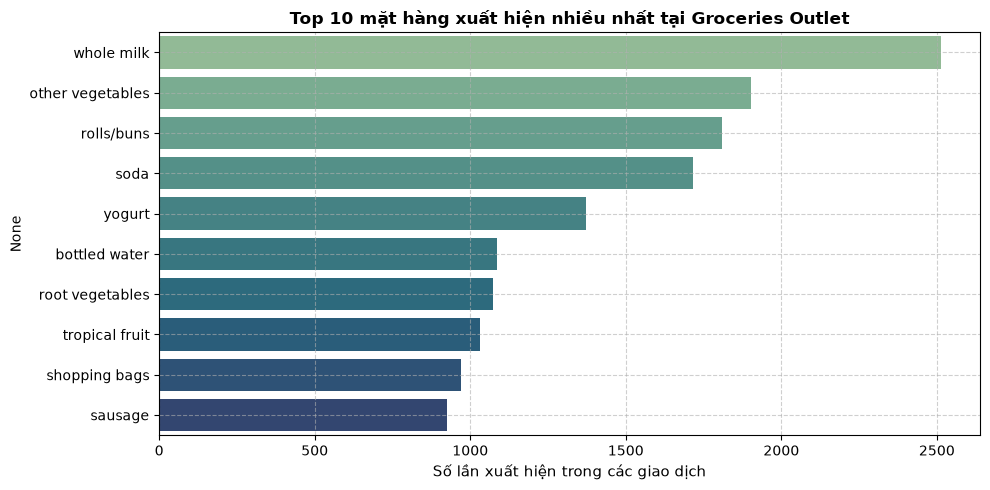

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


path = get_data_path('groceries.csv')
with open(path, 'r', encoding='utf-8') as f:
    transactions = [line.strip().split(',') for line in f if line.strip()]

# 1. Chuyển đổi sang One-Hot bằng TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)

print("--- KÍCH THƯỚC MA TRẬN DỮ LIỆU ONE-HOT ---")
print(f"Số lượng giao dịch (dòng): {df_groceries.shape[0]}")
print(f"Số lượng mặt hàng phân biệt (cột): {df_groceries.shape[1]}")

# 2. Thống kê Top 10 mặt hàng xuất hiện phổ biến nhất
item_frequencies = df_groceries.sum().sort_values(ascending=False)
print("\n--- TOP 10 MẶT HÀNG PHỔ BIẾN NHẤT ---")
for item, count in item_frequencies.head(10).items():
    print(f"• {item:25s}: {count:4d} lần ({round(count/len(df_groceries)*100, 2)}%)")

# Vẽ biểu đồ Top 10 mặt hàng
plt.figure(figsize=(10, 5))
sns.barplot(x=item_frequencies.head(10).values, y=item_frequencies.head(10).index, palette='crest')
plt.title("Top 10 mặt hàng xuất hiện nhiều nhất tại Groceries Outlet", fontsize=12, fontweight='bold')
plt.xlabel("Số lần xuất hiện trong các giao dịch", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Nhận xét Câu 2:
- Ma trận One-Hot gồm **9.835 dòng** và đúng **169 cột** (tương ứng 169 mặt hàng phân biệt).
- Mặt hàng bán chạy nhất là sữa tươi nguyên chất (`whole milk`) với 2.513 lần xuất hiện (chiếm 25.55% tổng số giao dịch), kế tiếp là các loại rau củ (`other vegetables` 19.35%), bánh mì cuộn (`rolls/buns` 18.39%), soda (17.44%), sữa chua (`yogurt` 13.95%).
